#Titulo tentativo: "Monitoreo satelital del comportamiento y pérdida de la cobertura vegetal por actividad minera informal en La Pampa, Madre de Dios"

Integrantes: Camilo Villarroel y Luis Angel Castillo.


##Pasos previos

Se buscaron repositorios del tema en cuestión, para interiorizarnos en trabajos previos.

se encontraron los siguientes github:
https://github.com/argenismarin/MineLab/tree/main
https://github.com/natannvw/Remote-Sensing-for-Mineral-Exploration-Demo/tree/main
https://github.com/earthrise-media/mining-detector

Se probaron los repositorios en sesiones propias del google colab para revisar su efectividad (disponibles en la carpeta del drive “pruebas repositorios”).
Se recopiló información satelital de dos bases de datos
DataSet ‘ESA WorldCover 100m v200’ para obtener la imagen satelital del 2021 y la elaboración de mapas temáticos que nos permitieron explorar la zona de estudio.
https://developers.google.com/earth-engine/datasets/catalog/ESA_WorldCover_v200?hl=es-419
DataSet ‘Harmonized Sentinel-2 MSI: MultiSpectral Instrument, Level-2A (SR)’ para el análisis temporal
https://developers.google.com/earth-engine/datasets/catalog/COPERNICUS_S2_SR_HARMONIZED?hl=es-419


In [ ]:
!pip install -q rioxarray

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 72.4/72.4 kB 3.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.4/1.4 MB 38.0 MB/s eta 0:00:00


In [ ]:

import ee
import requests
import numpy as np
import matplotlib.pyplot as plt
import rioxarray
from rasterio.enums import Resampling


In [ ]:
ee.Authenticate(auth_mode='notebook')



To authorize access needed by Earth Engine, open the following URL in a web browser and follow the instructions. If the web browser does not start automatically, please manually browse the URL below.

    https://code.earthengine.google.com/client-auth?scopes=https%3A//www.googleapis.com/auth/earthengine%20https%3A//www.googleapis.com/auth/cloud-platform%20https%3A//www.googleapis.com/auth/drive%20https%3A//www.googleapis.com/auth/devstorage.full_control&request_id=_DuYgE71Jvhe_lmeUS273r9Yzkh_1eD7SpTHvpfOz2M&tc=jFb0TpTAdqiMonJuG0Tld5-sjmfsYBw3VpNt2bIGzSc&cc=f3zkrgEVY4rCYq9HFcLwtF2wBygfTfCd4sBmSfhyiJ4

The authorization workflow will generate a code, which you should paste in the box below.
Enter verification code: 4/1AXlqoi4g8bdmHOaHEDfZJxSZ1vVfXKBt5uzEvZVhCMUu9Re7ZhL2U-BI68I

Successfully saved authorization token.


In [ ]:
PROJECT_ID = 'camilo-geocomputacion'
ee.Initialize(project=PROJECT_ID)

##Área de estudio

Se buscó determinar un área de estudio en la zona de madre de díos en donde sean visibles las dinámicas a estudiar.
Sin embargo se presentaron ciertas dificultades, debido a que no se podía insertar el BBOX original debido a tener dimensiones muy extensas.
Se buscaron distintas alternativas, sin embargo hubieron complicaciones buscando áreas que cumplan las condiciones tanto en extensión como en interés de estudio.
Además tuvimos leves confusiones respecto al orden de las latitudes y longitudes.

Se optó por un área de 2 kilómetros cuadrados que mezcla zona urbana, con bosque prístino, cultivos y suelo desnudo producto de la minería.
BBOX= [-69.95, -12.908, -69.93, -12.895]

Este BBOX se denominó “region”.


In [ ]:
# lon_min, lat_min, lon_max, lat_max
BBOX = [-69.95, -12.908, -69.93, -12.895]
region = ee.Geometry.Rectangle(BBOX)

print("Conexión exitosa:", ee.String("Google Earth Engine activo").getInfo())

Conexión exitosa: Google Earth Engine activo



##3. Descargar imagen recortada de GEE como GeoTIFF

Se buscó descargar una imagen satelital desde Google Earth Engine para luego descargarla como GeoTIFF; delimitada por el BBOX "region".

Luego, la imagen de cobertura del suelo ESA WorldCover, selecciona la banda "Map" y la descarga con una resolución de 10 metros

*en este paso se utilizó ia para el codigo de descarga *

In [ ]:
def descargar(img, nombre, escala):
    url = img.getDownloadURL({
        "region": region,
        "scale": escala,
        "crs": "EPSG:4326",
        "format": "GEO_TIFF",
    })
    r = requests.get(url, timeout=300)
    r.raise_for_status()
    with open(nombre, "wb") as f:
        f.write(r.content)
    print(nombre, f"{len(r.content) / 1e6:.1f} MB")
    return rioxarray.open_rasterio(nombre).squeeze("band", drop=True)

In [ ]:
%%time
wc_img = ee.ImageCollection("ESA/WorldCover/v200").first().select("Map")
wc = descargar(wc_img, "worldcover_gee.tif", 10)
print(wc.rio.crs, wc.rio.resolution(), wc.shape)

worldcover_gee.tif 0.0 MB
EPSG:4326 (8.983152841195215e-05, -8.983152841195215e-05) (146, 223)
CPU times: user 48.4 ms, sys: 9.56 ms, total: 58 ms
Wall time: 1.02 s


In [ ]:
#aquí se uso ia
import geemap

wc_img = ee.ImageCollection("ESA/WorldCover/v200").first().select("Map")

nombre_archivo = "área_dato_crudo_gee.tif"

#Exportar
geemap.ee_export_image(
    wc_img,
    filename=nombre_archivo,
    scale=10,
    region=region,
    crs="EPSG:4326",
    file_per_band=False
)

#Leer con rioxarray
wc = rioxarray.open_rasterio(nombre_archivo).squeeze("band", drop=True)
print(wc.rio.crs, wc.rio.resolution(), wc.shape)

Generating URL ...
Please wait ...
Data downloaded to /content/área_dato_crudo_gee.tif
EPSG:4326 (8.983152841195215e-05, -8.983152841195215e-05) (146, 223)


##Definición de cmap
Lo siguiente realizado fue determinar la paleta de colores con la que se va a trabajar para visualizar de mejor manera los diferentes elementos del área de estudio.
para esto se buscó en https://matplotlib.org/stable/users/explain/colors/colormaps.html
Se optó por “Accent” debido a que de tipo categorías son discretas (sin una gradiente o desvanecimiento) y tiene colores diferenciables cosa que se adapta a nuestro tipo de elementos.

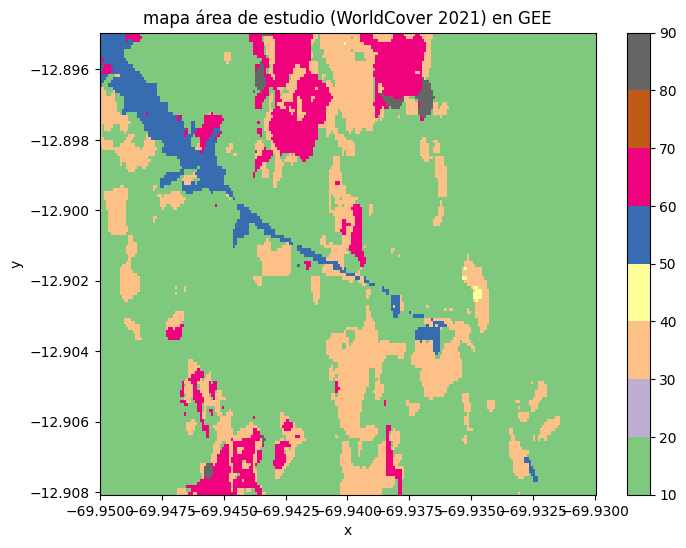

In [ ]:
wc.plot(cmap="Accent",figsize=(8, 6))
plt.title("mapa área de estudio (WorldCover 2021) en GEE")
plt.show()

##Definición de categorías

A partir de lo que se puede observar en una imagen satelital en “True Color” se determinaron las categorías tentativas:
Bosque amazónico		⇒ 10
Zona talada			⇒ 30
Cultivos			⇒ 40
Urbano 			⇒ 50
Minería (suelo desnudo)1 	⇒ 60
Agua				⇒ 80
Indeterminado 		⇒ 90

A cada categoría se le asignó un valor dentro de la paleta de colores “Accent”, proveniente de la fuente Matplotlib para su identificación dentro del área de estudio.

1  La categoría “minería (suelo desnudo)” es provisional, ya que aún queda pendiente el tratamiento de los datos para una clasificación más específica.

 10  bosque amazónico      75.9 %
 30  zona talada           13.7 %
 40  terreno cultivado      0.1 %
 50  Urbano                 3.6 %
 60  Minería(Suelo desnudo)   6.2 %
 80  Agua                   0.5 %
 90  indeterminado          0.0 %


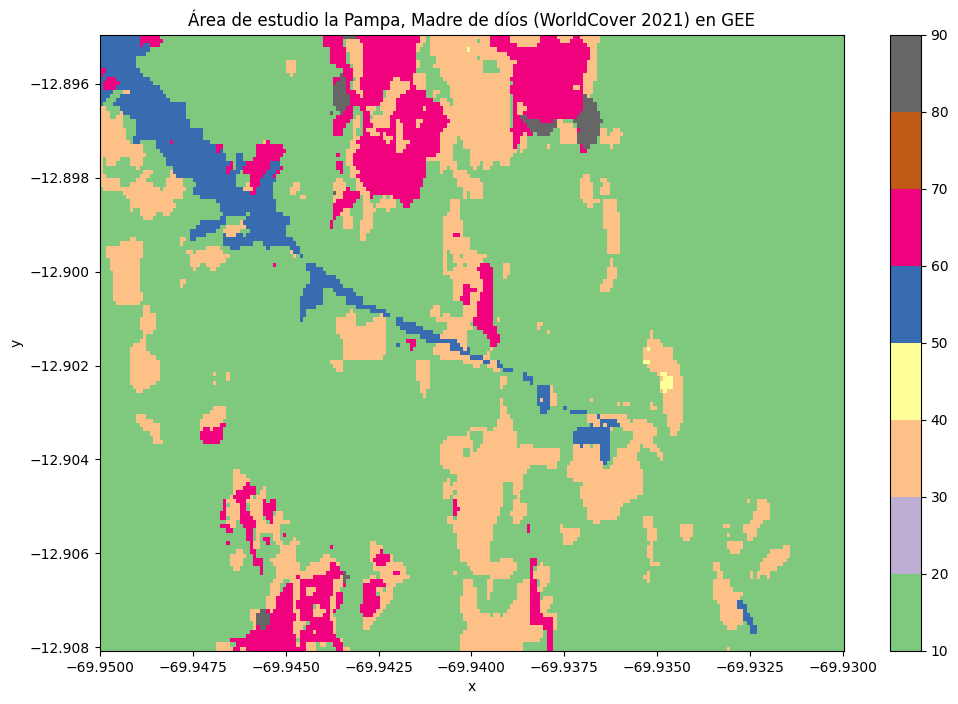

In [ ]:
CLASES = {
    10: "bosque amazónico", 30: "zona talada", 40: "terreno cultivado", 50: "Urbano",
    60: "Minería(Suelo desnudo)", 80: "Agua", 90: "indeterminado"
}

codigos, cuentas = np.unique(wc.values, return_counts=True)
for cod, k in zip(codigos, cuentas):
    print(f"{cod:>3}  {CLASES.get(int(cod), '?'):<20} {100 * k / cuentas.sum():5.1f} %")

wc.plot(cmap="Accent",figsize=(12, 8))
plt.title("Área de estudio la Pampa, Madre de díos (WorldCover 2021) en GEE")
plt.show()

##Gráfico % cobertura
Se realizó un gráfico de barras de la cobertura por categoría a partir del resultado obtenido.
fue realizado a partir de matplotlib


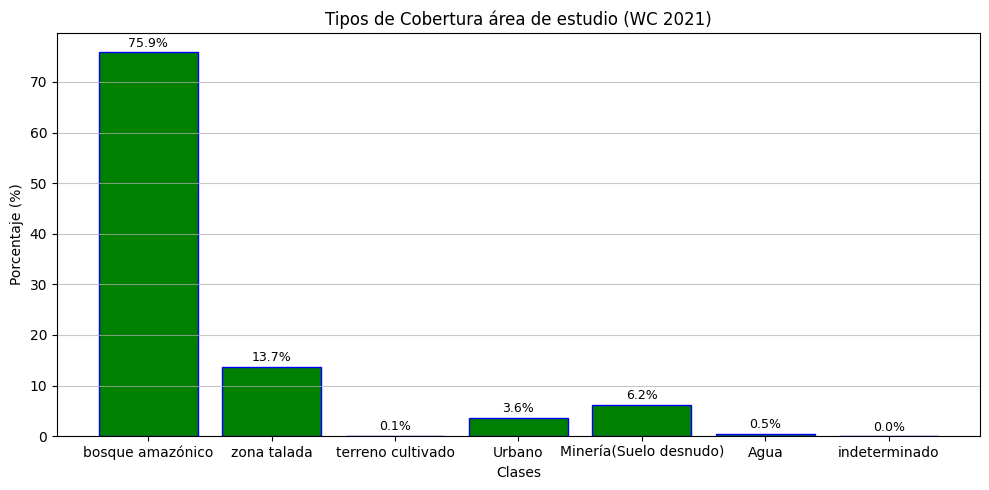

In [ ]:
import matplotlib.pyplot as plt

etiquetas = [CLASES.get(int(cod), "bosque amazónico") for cod in codigos] #se uso ia
porcentajes = 100 * cuentas / cuentas.sum()

plt.figure(figsize=(10, 5))
barras = plt.bar(etiquetas, porcentajes, color='green', edgecolor='blue')

# se uso ia aquí
for barra in barras:
    yval = barra.get_height()
    plt.text(barra.get_x() + barra.get_width()/2.0, yval + 0.5, f'{yval:.1f}%', ha='center', va='bottom', fontsize=9)


plt.title("Tipos de Cobertura área de estudio (WC 2021)")
plt.xlabel("Clases")
plt.ylabel("Porcentaje (%)")
plt.grid(axis='y', alpha=0.7)
plt.tight_layout()

plt.show()

## Filtros para las imágenes satelitales

A partir del DataSet de ‘Harmonized Sentinel-2 MSI: MultiSpectral Instrument, Level-2A (SR)’ se solicitó mediante un código que se escogiera escenas con una nubosidad menor a 20% en el periodo de 01/09/2026 al 01/10/2026, dentro del área de estudio del BBOX denominada “region”.

Esto dio como resultado 6 escenas, de las cuales escogió a la que tenía menor cantidad de nubosidad (0.64%) en la fecha del 17/09/2026.
ee.ImageCollection(“Copernicus/S2:SR_HARMONIZED”)
La imagen seleccionada fue: 20260917T144729_20260917T144728_T19LCF


In [ ]:
coleccion = (
    ee.ImageCollection("COPERNICUS/S2_SR_HARMONIZED")
    .filterBounds(region)
    .filterDate("2026-09-01", "2026-10-01")
    .filter(ee.Filter.lt("CLOUDY_PIXEL_PERCENTAGE", 20))#cambiar
)
n = coleccion.size().getInfo()
assert n > 0, "Ninguna escena cubre el área completo; amplía las fechas o el umbral de nubes"
print(n, "escenas")

escena = coleccion.sort("CLOUDY_PIXEL_PERCENTAGE").first()
print(escena.get("system:index").getInfo(), escena.get("CLOUDY_PIXEL_PERCENTAGE").getInfo(), "% nubes")

6 escenas
20260917T144729_20260917T144728_T19LCF 0.636946 % nubes


##Índice NDVi

A manera de explorar la información de la imagen seleccionada, se le aplicó un Índice de Vegetación de Diferencia Normalizada.
Se tomó la imagen normalizada, se renombró como NDVI y se realizó una operación: B8-B4. Luego, el resultado llamado NDVI toma la imagen, la transforma en un Geotiff con una resolución de 10 píxeles.
Para mostrar la imagen, se usó la paleta de colores ‘RdYlGn’, ya que esta gradiente permite contrastar notoriamente las zonas sin vegetación / vegetación dañada en color rojo y amarillo, y las que sí tienen vegetación saludable de verde.
Se definió como valor mínimo: -0.2; y como valor máximo 1 para el rango de la paleta, con la finalidad de identificar las zonas intervenidas.


In [ ]:
%%time
ndvi_img = escena.normalizedDifference(["B8", "B4"]).rename("NDVI") #NDVI B8-B4
ndvi = descargar(ndvi_img, "ndvi_gee.tif", 10)
print(ndvi.shape, float(ndvi.min()), float(ndvi.max())) #elimina máximos y mínimos

ndvi_gee.tif 0.1 MB
(146, 223) -0.5104947686195374 0.9033339619636536
CPU times: user 14.8 ms, sys: 4.55 ms, total: 19.3 ms
Wall time: 1.02 s


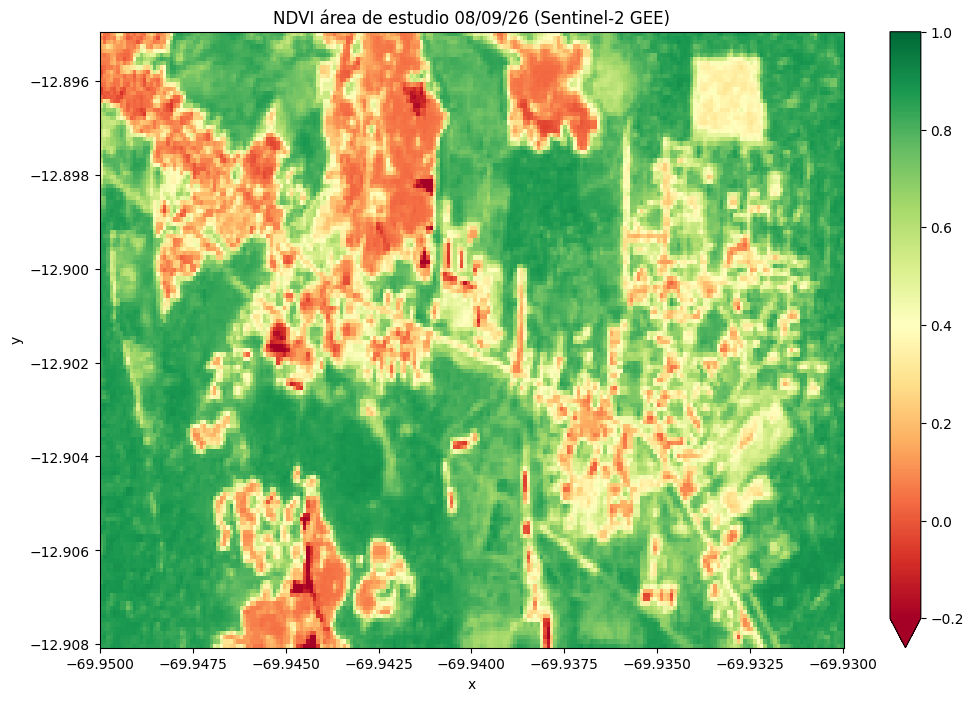

In [ ]:
ndvi.plot(cmap="RdYlGn", vmin=-0.2, vmax=01.0, figsize=(12, 8))
plt.title("NDVI área de estudio 08/09/26 (Sentinel-2 GEE)")
plt.show()

##Comparación temporal
Posteriormente, para hacer una comparación temporal, bajo los mismos criterios y usando el mismo DataSet, se obtuvo una escena del 08/09/2021 con una nubosidad de 2.6% dentro la misma región.
Periodo solicitado 01/09/2021 a 01/10/2021


In [ ]:
coleccion = (
    ee.ImageCollection("COPERNICUS/S2_SR_HARMONIZED")
    .filterBounds(region)
    .filterDate("2021-09-01", "2021-10-01")
    .filter(ee.Filter.lt("CLOUDY_PIXEL_PERCENTAGE", 20))#cambiar
)
n = coleccion.size().getInfo()
assert n > 0, "Ninguna escena cubre el área completo; amplía las fechas o el umbral de nubes"
print(n, "escenas")

escena = coleccion.sort("CLOUDY_PIXEL_PERCENTAGE").first()
print(escena.get("system:index").getInfo(), escena.get("CLOUDY_PIXEL_PERCENTAGE").getInfo(), "% nubes")

6 escenas
20210908T144731_20210908T145544_T19LCF 2.632956 % nubes


In [ ]:
%%time
ndvi_img = escena.normalizedDifference(["B8", "B4"]).rename("NDVI") #NDVI
ndvi = descargar(ndvi_img, "ndvi_gee.tif", 10)
print(ndvi.shape, float(ndvi.min()), float(ndvi.max())) # elimina máximos y mínimos

ndvi_gee.tif 0.1 MB
(146, 223) -0.9277108311653137 0.9894266128540039
CPU times: user 17 ms, sys: 2.03 ms, total: 19 ms
Wall time: 879 ms


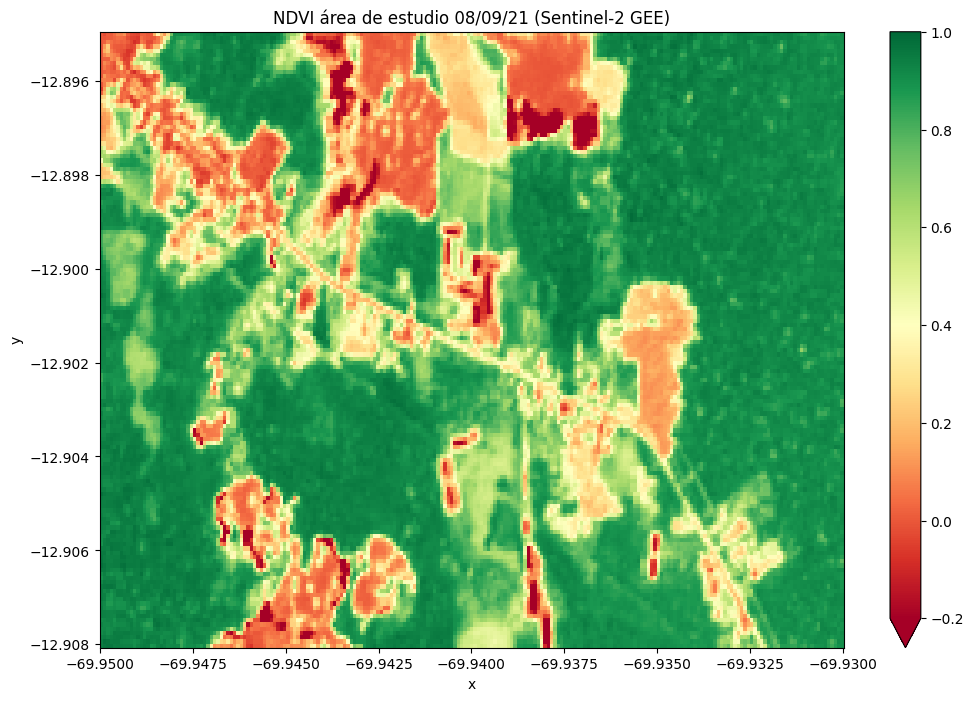

In [ ]:
ndvi.plot(cmap="RdYlGn", vmin=-0.2, vmax=01.0, figsize=(12, 8))
plt.title("NDVI área de estudio 08/09/21 (Sentinel-2 GEE)")
plt.show()